In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Open Datasets Folder

In [2]:
dataset_path = "/kaggle/input/datasets/fihabefti/tealeaf/TeaLeaf-4"

print(os.listdir(dataset_path))

['Healthy', 'RedSpider', 'Skeletonization', 'Sun_lightScorching']


# Count Images in Each Class 

In [3]:
classes = os.listdir(dataset_path)

total_images = 0

for class_name in classes:

    class_path = os.path.join(dataset_path, class_name)

    files = os.listdir(class_path)

    image_count = 0

    for file in files:

        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            image_count = image_count + 1

    print(class_name, ":", image_count)

    total_images = total_images + image_count

print("Total Images:", total_images)

Healthy : 1108
RedSpider : 1061
Skeletonization : 594
Sun_lightScorching : 393
Total Images: 3156


# **Check Dataset Size**

In [4]:
dataset_size = 0

for root, folders, files in os.walk(dataset_path):

    for file in files:

        file_path = os.path.join(root, file)

        dataset_size = dataset_size + os.path.getsize(file_path)

size_gb = dataset_size / (1024 ** 3)

print("Total Dataset Size:", round(size_gb, 3), "GB")

Total Dataset Size: 1.87 GB


# Check Image Resolution and RGB Channels

In [6]:
from PIL import Image
classes = os.listdir(dataset_path)

for class_name in classes:

    class_path = os.path.join(dataset_path, class_name)

    files = os.listdir(class_path)

    for file in files:

        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            image_path = os.path.join(class_path, file)

            image = Image.open(image_path)

            width, height = image.size

            print("Class:", class_name)
            print("Image Name:", file)
            print("Width:", width)
            print("Height:", height)
            print("Color Mode:", image.mode)
            print("Channels:", len(image.getbands()))

            print("----------------------------")

            break

Class: Healthy
Image Name: 20250524_210609.png
Width: 3000
Height: 3000
Color Mode: RGB
Channels: 3
----------------------------
Class: RedSpider
Image Name: 20250524_210638.png
Width: 3000
Height: 3000
Color Mode: RGB
Channels: 3
----------------------------
Class: Skeletonization
Image Name: 20250524_210801.png
Width: 3000
Height: 3000
Color Mode: RGB
Channels: 3
----------------------------
Class: Sun_lightScorching
Image Name: 20250524_211524.png
Width: 3000
Height: 3000
Color Mode: RGB
Channels: 3
----------------------------


# Corrupted Image Audit

In [7]:
resolution_count = {}
rgb_count = 0
non_rgb_count = 0
total_checked = 0

for class_name in classes:

    class_path = os.path.join(dataset_path, class_name)

    files = os.listdir(class_path)

    for file in files:

        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            image_path = os.path.join(class_path, file)

            try:
                image = Image.open(image_path)

                width, height = image.size

                resolution = (width, height)

                if resolution in resolution_count:
                    resolution_count[resolution] += 1
                else:
                    resolution_count[resolution] = 1

                if image.mode == "RGB":
                    rgb_count += 1
                else:
                    non_rgb_count += 1

                total_checked += 1

                image.close()

            except:
                print("Error:", image_path)

print("Total Images Checked:", total_checked)

print("\nResolution Distribution:")

for resolution, count in resolution_count.items():
    print(resolution, ":", count)

print("\nRGB Images:", rgb_count)
print("Non-RGB Images:", non_rgb_count)

Total Images Checked: 3156

Resolution Distribution:
(3000, 3000) : 3156

RGB Images: 3156
Non-RGB Images: 0


# Duplicate Image Audit

In [8]:
import hashlib
image_hashes = {}

duplicate_images = []

for class_name in classes:

    print("Checking:", class_name)

    class_path = os.path.join(dataset_path, class_name)

    files = os.listdir(class_path)

    for file in files:

        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            image_path = os.path.join(class_path, file)

            with open(image_path, "rb") as image_file:

                image_data = image_file.read()

            image_hash = hashlib.sha256(image_data).hexdigest()

            if image_hash in image_hashes:

                duplicate_images.append(image_path)

            else:

                image_hashes[image_hash] = image_path


print("\nTotal Unique Images:", len(image_hashes))

print("Duplicate Images:", len(duplicate_images))

Checking: Healthy
Checking: RedSpider
Checking: Skeletonization
Checking: Sun_lightScorching

Total Unique Images: 3155
Duplicate Images: 1


# **Find Duplicate Image Location**

In [9]:
for duplicate_path in duplicate_images:

    with open(duplicate_path, "rb") as image_file:

        image_data = image_file.read()

    image_hash = hashlib.sha256(image_data).hexdigest()

    original_path = image_hashes[image_hash]

    print("Original Image:", original_path)

    print("Duplicate Image:", duplicate_path)

    print("Original Class:",
          os.path.basename(os.path.dirname(original_path)))

    print("Duplicate Class:",
          os.path.basename(os.path.dirname(duplicate_path)))

    print("----------------------------")

Original Image: /kaggle/input/datasets/fihabefti/tealeaf/TeaLeaf-4/RedSpider/IMG_20250525_173838.jpg
Duplicate Image: /kaggle/input/datasets/fihabefti/tealeaf/TeaLeaf-4/Sun_lightScorching/IMG_20250525_173838.jpg
Original Class: RedSpider
Duplicate Class: Sun_lightScorching
----------------------------


# Display Duplicate Image

Duplicate Image:
File Name: IMG_20250525_173838.jpg
Image Size: (3000, 3000)
Image Mode: RGB


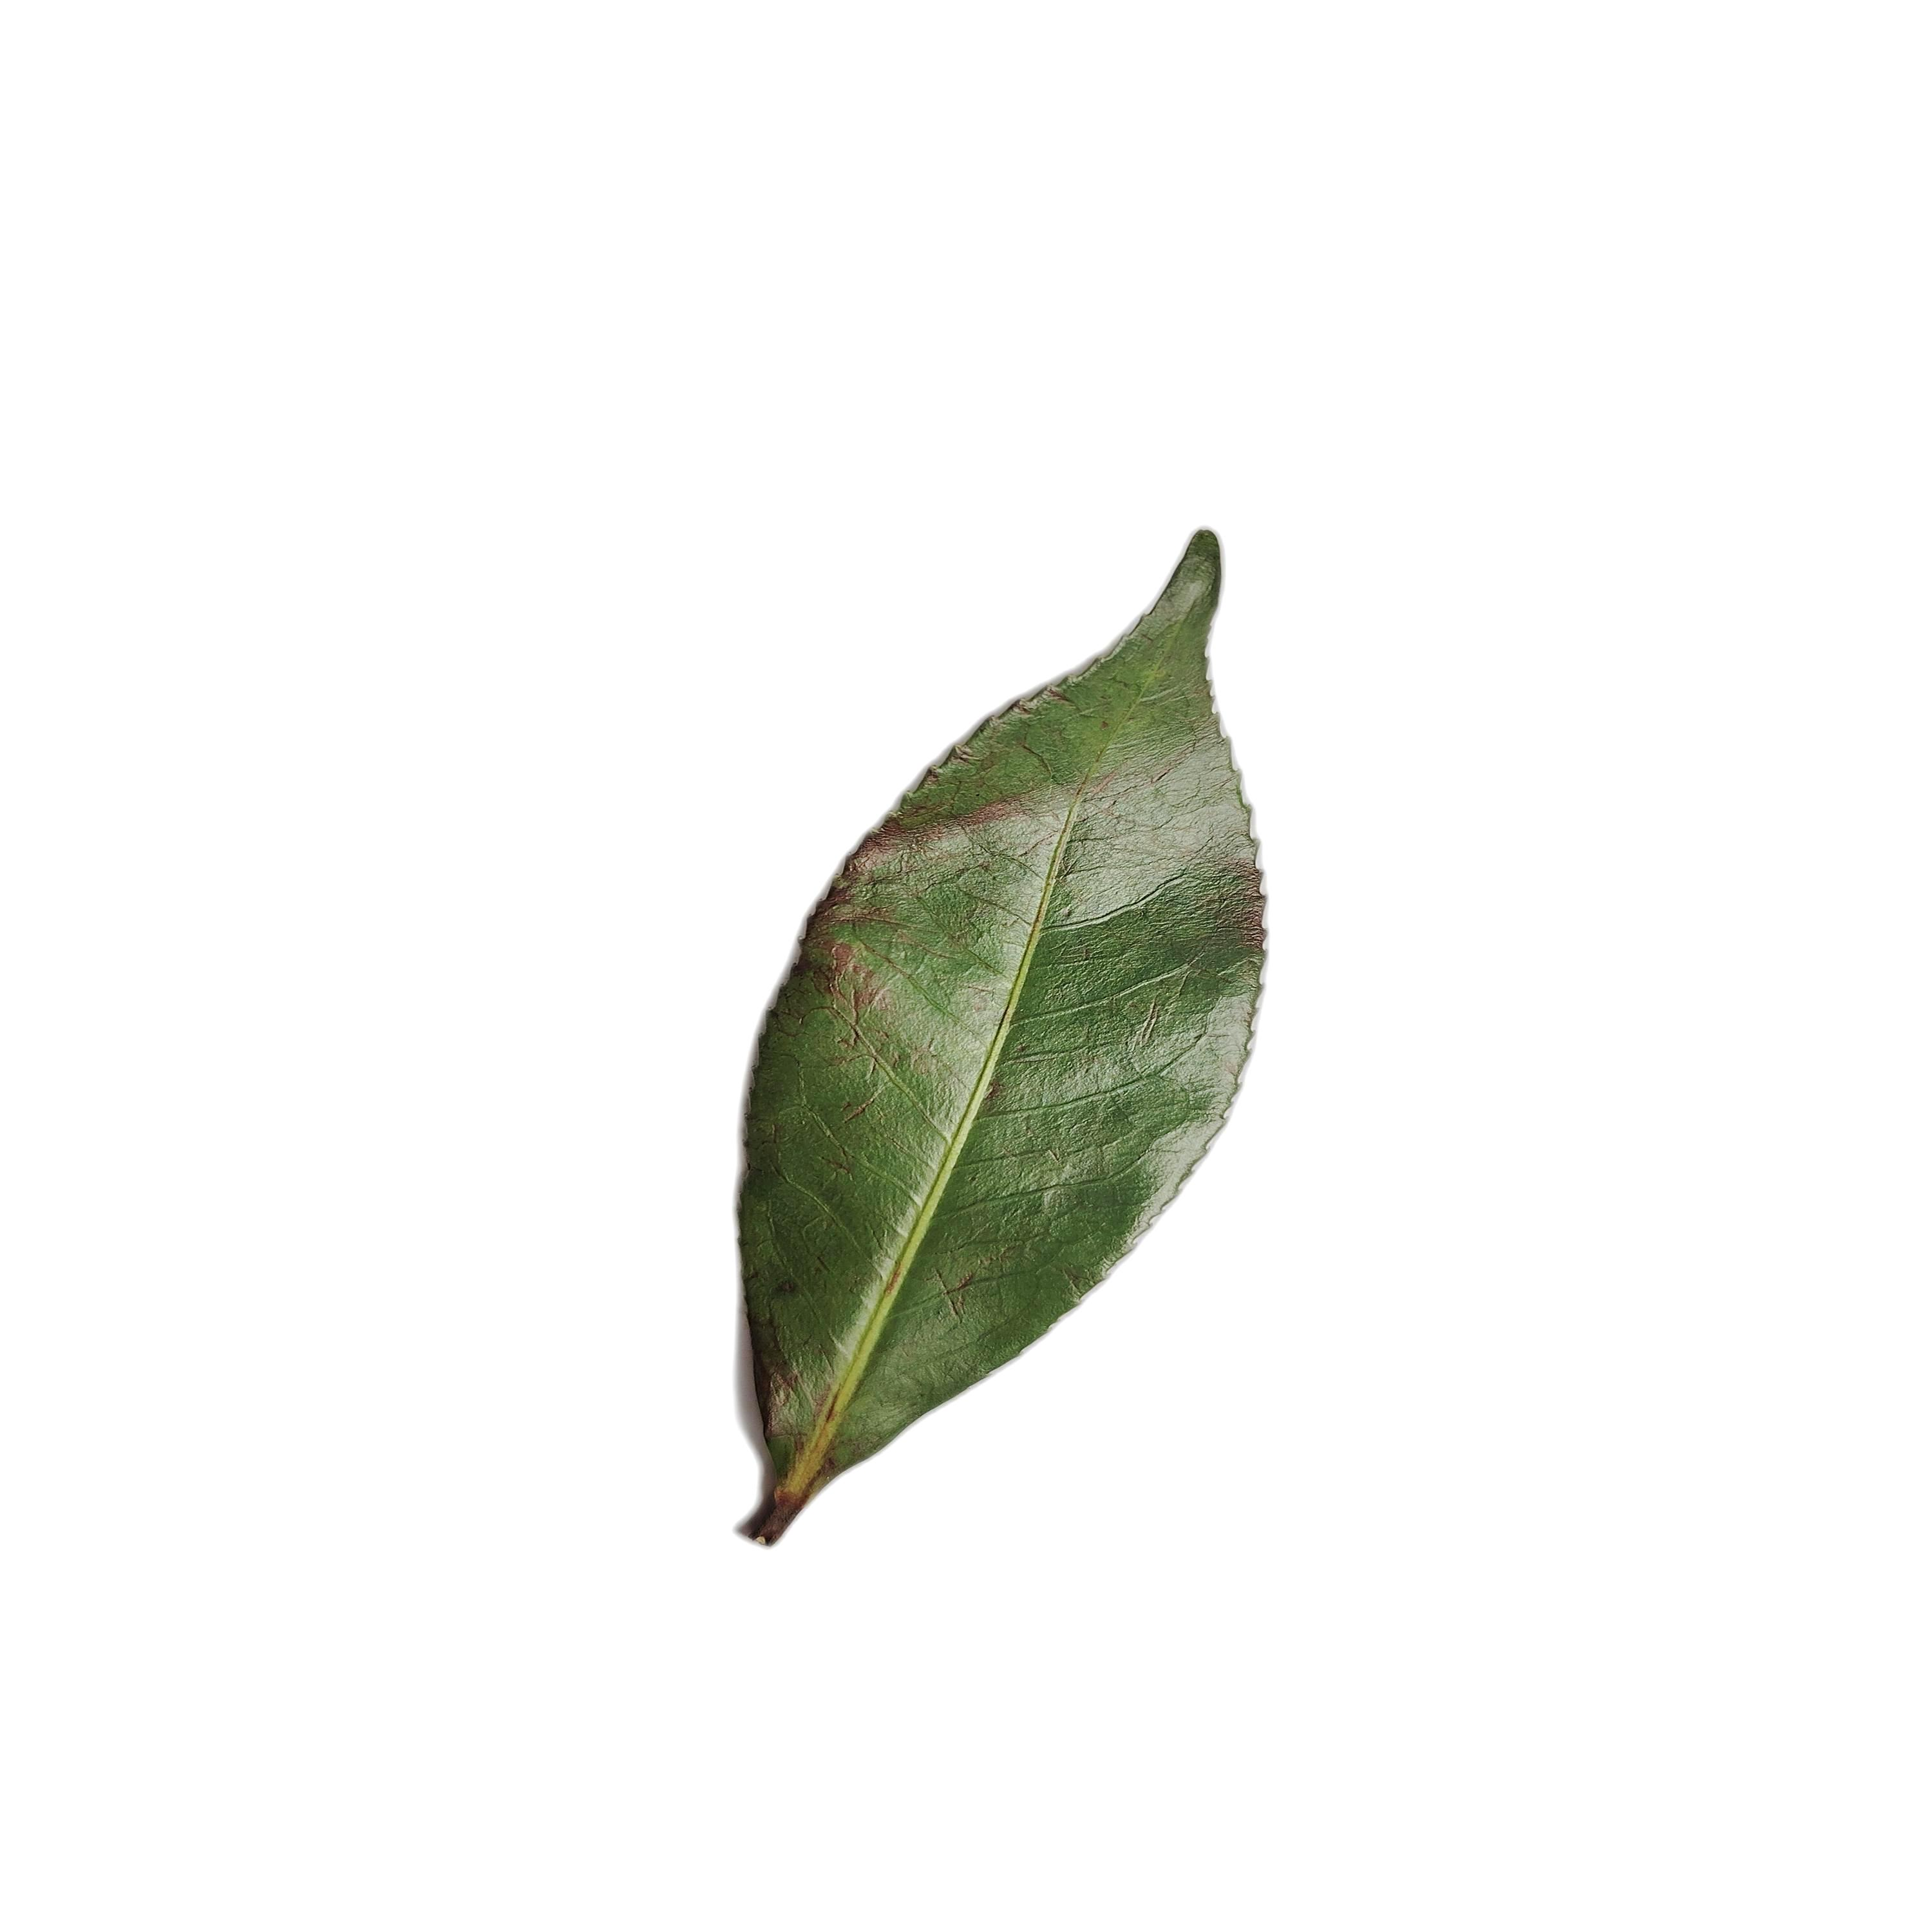

In [10]:
duplicate_path = duplicate_images[0]

image = Image.open(duplicate_path)

print("Duplicate Image:")
print("File Name:", os.path.basename(duplicate_path))
print("Image Size:", image.size)
print("Image Mode:", image.mode)

display(image)

# Verify Clean Dataset

In [11]:

# Create Clean Dataset Path

import shutil
clean_dataset_path = "/kaggle/working/TeaLeaf-4-Clean"

# Identify Both Duplicate Images

duplicate_original = os.path.join(
    dataset_path,
    "RedSpider",
    "IMG_20250525_173838.jpg"
)

duplicate_copy = os.path.join(
    dataset_path,
    "Sun_lightScorching",
    "IMG_20250525_173838.jpg"
)

# Create Clean Dataset Folder

os.makedirs(clean_dataset_path, exist_ok=True)


clean_total = 0

for class_name in classes:

    class_path = os.path.join(dataset_path, class_name)

    clean_class_path = os.path.join(clean_dataset_path, class_name)

    os.makedirs(clean_class_path, exist_ok=True)

    files = os.listdir(class_path)

    image_count = 0

    for file in files:

        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            image_path = os.path.join(class_path, file)

            # Skip Both Duplicate Images
            if image_path == duplicate_original or image_path == duplicate_copy:

                continue

            # Copy Remaining Images
            shutil.copy2(image_path, clean_class_path)

            image_count = image_count + 1

    print(class_name, ":", image_count)

    clean_total = clean_total + image_count

print("Total Clean Images:", clean_total)


Healthy : 1108
RedSpider : 1060
Skeletonization : 594
Sun_lightScorching : 392
Total Clean Images: 3154


# Import and Folder setup for Spliting

In [12]:
split_dataset_path = "/kaggle/working/TeaLeaf-4-Split-70-15-15"

train_dir = os.path.join(split_dataset_path, "train")
val_dir = os.path.join(split_dataset_path, "validation")
test_dir = os.path.join(split_dataset_path, "test")

os.makedirs(train_dir, exist_ok=True)
os.makedirs(val_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)

print("Training Folder:", train_dir)
print("Validation Folder:", val_dir)
print("Testing Folder:", test_dir)

Training Folder: /kaggle/working/TeaLeaf-4-Split-70-15-15/train
Validation Folder: /kaggle/working/TeaLeaf-4-Split-70-15-15/validation
Testing Folder: /kaggle/working/TeaLeaf-4-Split-70-15-15/test


In [13]:
clean_total = 0

for class_name in classes:

    class_path = os.path.join(clean_dataset_path, class_name)

    files = os.listdir(class_path)

    image_count = 0

    for file in files:

        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            image_count = image_count + 1

    print(class_name, ":", image_count)

    clean_total = clean_total + image_count

print("Total Clean Images:", clean_total)

Healthy : 1108
RedSpider : 1060
Skeletonization : 594
Sun_lightScorching : 392
Total Clean Images: 3154


# Perform Stratified Split

In [14]:
train_total = 0
val_total = 0
test_total = 0

for class_name in classes:

    class_path = os.path.join(clean_dataset_path, class_name)

    train_class_path = os.path.join(train_dir, class_name)
    val_class_path = os.path.join(val_dir, class_name)
    test_class_path = os.path.join(test_dir, class_name)

    os.makedirs(train_class_path, exist_ok=True)
    os.makedirs(val_class_path, exist_ok=True)
    os.makedirs(test_class_path, exist_ok=True)

    files = os.listdir(class_path)

    image_files = []

    for file in files:

        if file.lower().endswith((".jpg", ".jpeg", ".png")):

            image_files.append(file)

    np.random.shuffle(image_files)

    train_index = int(round(len(image_files) * 0.70))

    train_files = image_files[:train_index]

    remaining_files = image_files[train_index:]

    val_index = int(len(remaining_files) * 0.5)

    val_files = remaining_files[:val_index]

    test_files = remaining_files[val_index:]

    for file in train_files:

        source_path = os.path.join(class_path, file)

        shutil.copy2(source_path, train_class_path)

    for file in val_files:

        source_path = os.path.join(class_path, file)

        shutil.copy2(source_path, val_class_path)

    for file in test_files:

        source_path = os.path.join(class_path, file)

        shutil.copy2(source_path, test_class_path)

    print(class_name)
    print("Training Images:", len(train_files))
    print("Validation Images:", len(val_files))
    print("Testing Images:", len(test_files))
    print("--------------------------")

    train_total = train_total + len(train_files)
    val_total = val_total + len(val_files)
    test_total = test_total + len(test_files)

print("Total Training Images:", train_total)
print("Total Validation Images:", val_total)
print("Total Testing Images:", test_total)

print("Total Images:", train_total + val_total + test_total)

Healthy
Training Images: 776
Validation Images: 166
Testing Images: 166
--------------------------
RedSpider
Training Images: 742
Validation Images: 159
Testing Images: 159
--------------------------
Skeletonization
Training Images: 416
Validation Images: 89
Testing Images: 89
--------------------------
Sun_lightScorching
Training Images: 274
Validation Images: 59
Testing Images: 59
--------------------------
Total Training Images: 2208
Total Validation Images: 473
Total Testing Images: 473
Total Images: 3154


#  Download Important Library for Image Transform and Data Loading

In [15]:
# Core PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F

# Data + image transforms
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# Central Hyperparameter Configuration

In [17]:

IMG_SIZE = 128

# DataLoader Configuration
BATCH_SIZE = 32

# Training Configuration
EPOCHS = 25
LEARNING_RATE = 1e-3

# CNN Architecture Configuration
KERNEL_SIZE = 3
STRIDE= 1
FEATURE_MAPS = (16, 32, 64)
HIDDEN_UNITS = 64
NUM_CLASSES = 4

DROPOUT = 0.25

OPTIMIZER_NAME = "Adam"

PADDING = 1


print("IMAGE SIZE:", IMG_SIZE)
print("BATCH SIZE:", BATCH_SIZE)
print("EPOCHS:", EPOCHS)
print("LEARNING RATE:", LEARNING_RATE)
print("KERNEL SIZE:", KERNEL_SIZE)
print("Stride:", STRIDE)
print("FEATURE MAPS:", FEATURE_MAPS)
print("HIDDEN UNITS:", HIDDEN_UNITS)
print("NUMBER OF CLASSES:", NUM_CLASSES)
print("DROPOUT:", DROPOUT)
print("OPTIMIZER:", OPTIMIZER_NAME)
print("Padding:", PADDING)

IMAGE SIZE: 128
BATCH SIZE: 32
EPOCHS: 25
LEARNING RATE: 0.001
KERNEL SIZE: 3
Stride: 1
FEATURE MAPS: (16, 32, 64)
HIDDEN UNITS: 64
NUMBER OF CLASSES: 4
DROPOUT: 0.25
OPTIMIZER: Adam
Padding: 1


# LOAD THE IMAGE WITH BASIC TRANSFORM

In [20]:
basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])


train_ds = datasets.ImageFolder( train_dir, transform=basic_transform )

val_ds = datasets.ImageFolder( val_dir, transform=basic_transform )

test_ds = datasets.ImageFolder( test_dir, transform=basic_transform )

train_loader = DataLoader( train_ds, batch_size=BATCH_SIZE, shuffle=True )

val_loader = DataLoader( val_ds, batch_size=BATCH_SIZE, shuffle=False)

test_loader = DataLoader( test_ds, batch_size=BATCH_SIZE, shuffle=False )


print("Classes:", train_ds.classes)

print("Train images:", len(train_ds))
print("Val images:", len(val_ds))
print("Test images:", len(test_ds))

print("--------------------------")

print("Train batches:", len(train_loader))
print("Val batches:", len(val_loader))
print("Test batches:", len(test_loader))

Classes: ['Healthy', 'RedSpider', 'Skeletonization', 'Sun_lightScorching']
Train images: 2208
Val images: 473
Test images: 473
--------------------------
Train batches: 69
Val batches: 15
Test batches: 15


# Visualize Training Images

In [35]:
import matplotlib.pyplot as plt
import numpy as np
import os, urllib.request, zipfile
print("Configured Batch Size:", BATCH_SIZE)
print("DataLoader Batch Size:", train_loader.batch_size)
print("Training Dataset Size:", len(train_ds))

images, labels = next(iter(train_loader))

print("Actual Batch Shape:", images.shape)
print("Actual Images:", len(images))

Configured Batch Size: 32
DataLoader Batch Size: 32
Training Dataset Size: 2208
Actual Batch Shape: torch.Size([32, 3, 128, 128])
Actual Images: 32


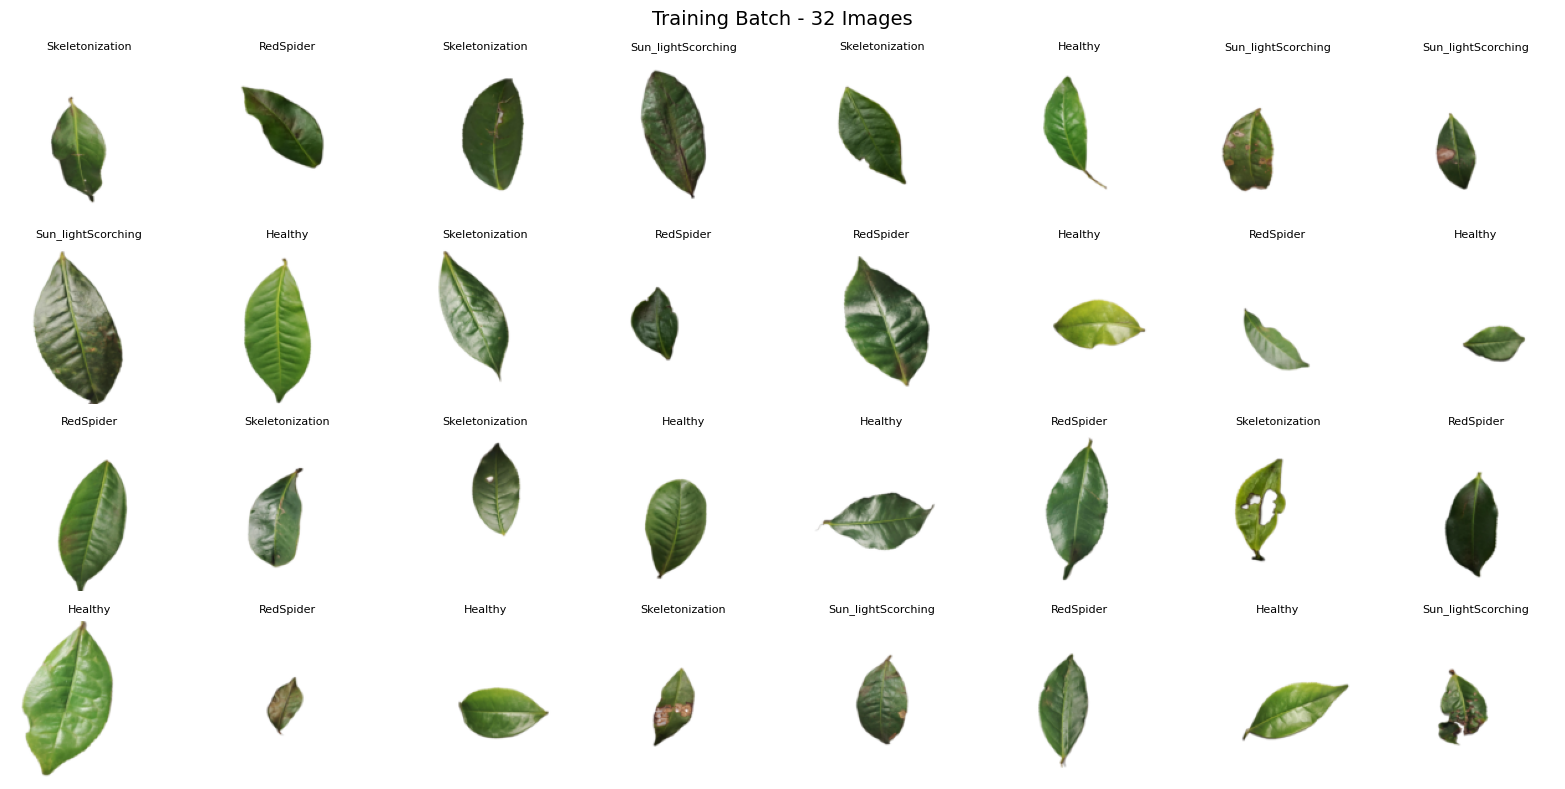

In [36]:

# Grab one batch
images, labels = next(iter(train_loader))

class_names = train_ds.classes

# Display available images (maximum 32)
num_images = min(BATCH_SIZE, len(images))

plt.figure(figsize=(16, 8))

for i in range(num_images):

    plt.subplot(4, 8, i + 1)

    # Convert Tensor (C, H, W) to Image (H, W, C)
    plt.imshow(images[i].permute(1, 2, 0))

    plt.title(class_names[labels[i].item()], fontsize=8)

    plt.axis("off")

plt.suptitle(
    f"Training Batch - {num_images} Images", fontsize=14 )

plt.tight_layout()
plt.show()


In [22]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Using device:", device)

Using device: cuda


# CNN ARCHITECTURE

In [42]:

class SimpleCNN(nn.Module):
    def __init__(self, p_dropout=DROPOUT):
        super().__init__()

        self.conv1 = nn.Conv2d( 3, FEATURE_MAPS[0], kernel_size=KERNEL_SIZE,stride=STRIDE, padding=PADDING )

        self.conv2 = nn.Conv2d( FEATURE_MAPS[0], FEATURE_MAPS[1], kernel_size=KERNEL_SIZE,stride=STRIDE, padding=PADDING )

        self.conv3 = nn.Conv2d( FEATURE_MAPS[1], FEATURE_MAPS[2], kernel_size=KERNEL_SIZE,stride=STRIDE, padding=PADDING )

        self.pool = nn.MaxPool2d(2, 2)


        self.dropout = nn.Dropout(p_dropout)

        self.fc1 = nn.Linear( FEATURE_MAPS[2] * (IMG_SIZE // 8) * (IMG_SIZE // 8), HIDDEN_UNITS )

        self.fc2 = nn.Linear( HIDDEN_UNITS,4)


    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))
        x = self.pool(F.relu(self.conv2(x)))
        x = self.pool(F.relu(self.conv3(x)))


        x = torch.flatten(x, 1)

        x = self.dropout(x)

        x = F.relu(self.fc1(x))
        x = self.fc2(x)

        return x


# Build the model and print it
model = SimpleCNN(p_dropout=DROPOUT).to(device)

print(model)

n_params = sum(p.numel() for p in model.parameters())

print(f"\nTotal trainable parameters: {n_params:,}")
print("Dropout:", model.dropout.p)
print("FC1:", model.fc1)
print("Image Size:", IMG_SIZE)
print("Convolution Stride:", STRIDE)


SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=16384, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=4, bias=True)
)

Total trainable parameters: 1,072,484
Dropout: 0.25
FC1: Linear(in_features=16384, out_features=64, bias=True)
Image Size: 128
Convolution Stride: 1


# Create Train_model Function

In [44]:

def train_model(model, train_loader, val_loader, test_loader, epochs=EPOCHS, lr=LEARNING_RATE):

    criterion = nn.CrossEntropyLoss()

    # Optimizer selection
    if OPTIMIZER_NAME == "Adam":
        optimizer = torch.optim.Adam(model.parameters(), lr=lr)

    elif OPTIMIZER_NAME == "SGD":
        optimizer = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9)

    # We record these each epoch so we can plot curves afterwards
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    # Best Model Checkpoint
    best_val_acc = 0.0
    best_epoch = 0

    for epoch in range(epochs):

        # ---------------- TRAINING ----------------
        model.train()
        running_loss, correct, total = 0.0, 0, 0

        for imgs, labels in train_loader:
            imgs, labels = imgs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(imgs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * imgs.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = correct / total

        # ---------------- VALIDATION ----------------
        model.eval()
        running_loss, correct, total = 0.0, 0, 0

        with torch.no_grad():
            for imgs, labels in val_loader:
                imgs, labels = imgs.to(device), labels.to(device)

                outputs = model(imgs)
                loss = criterion(outputs, labels)

                running_loss += loss.item() * imgs.size(0)
                correct += (outputs.argmax(1) == labels).sum().item()
                total += labels.size(0)

        val_loss = running_loss / total
        val_acc = correct / total

        # Save Best Model
        if val_acc > best_val_acc:

            best_val_acc = val_acc
            best_epoch = epoch + 1

            torch.save(
                model.state_dict(),
                "/kaggle/working/best_model_70_15_15.pth"
            )

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        print(f"Epoch {epoch+1:2d}/{epochs}  "
              f"train_loss={train_loss:.3f} train_acc={train_acc:.3f}  |  "
              f"val_loss={val_loss:.3f} val_acc={val_acc:.3f}")

    print("\nBest Validation Accuracy:", round(best_val_acc, 4))
    print("Best Epoch:", best_epoch)

    # ---------------- LOAD BEST MODEL ----------------
    model.load_state_dict(
        torch.load( "/kaggle/working/best_model_70_15_15.pth", map_location=device
        )
    )

    # ---------------- FINAL TESTING ----------------
    model.eval()
    running_loss, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for imgs, labels in test_loader:
            imgs, labels = imgs.to(device), labels.to(device)

            outputs = model(imgs)
            loss = criterion(outputs, labels)

            running_loss += loss.item() * imgs.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    test_loss = running_loss / total
    test_acc = correct / total

    print("\n========== FINAL TEST RESULTS ==========")
    print("Test Loss:", round(test_loss, 4))
    print("Test Accuracy:", round(test_acc, 4))

    return history


In [45]:
# Build a new model
model = SimpleCNN(p_dropout=DROPOUT).to(device)

# Train and evaluate
history = train_model(
    model,
    train_loader,
    val_loader,
    test_loader,
    epochs=EPOCHS,
    lr=LEARNING_RATE
)

Epoch  1/25  train_loss=1.320 train_acc=0.349  |  val_loss=1.300 val_acc=0.410
Epoch  2/25  train_loss=1.266 train_acc=0.404  |  val_loss=1.228 val_acc=0.452
Epoch  3/25  train_loss=1.197 train_acc=0.430  |  val_loss=1.198 val_acc=0.463
Epoch  4/25  train_loss=1.139 train_acc=0.482  |  val_loss=1.169 val_acc=0.514
Epoch  5/25  train_loss=1.058 train_acc=0.549  |  val_loss=1.167 val_acc=0.459
Epoch  6/25  train_loss=0.973 train_acc=0.584  |  val_loss=1.146 val_acc=0.514
Epoch  7/25  train_loss=0.918 train_acc=0.609  |  val_loss=1.140 val_acc=0.522
Epoch  8/25  train_loss=0.886 train_acc=0.635  |  val_loss=1.031 val_acc=0.550
Epoch  9/25  train_loss=0.821 train_acc=0.655  |  val_loss=1.067 val_acc=0.545
Epoch 10/25  train_loss=0.811 train_acc=0.659  |  val_loss=0.996 val_acc=0.584
Epoch 11/25  train_loss=0.735 train_acc=0.702  |  val_loss=1.059 val_acc=0.575
Epoch 12/25  train_loss=0.700 train_acc=0.717  |  val_loss=1.148 val_acc=0.573
Epoch 13/25  train_loss=0.661 train_acc=0.727  |  va

# Load the Best Model Checkpoint

In [27]:
model.load_state_dict(
    torch.load( "/kaggle/working/best_model_70_15_15.pth", map_location=device )
)

model.eval()

print("Best Model Loaded Successfully!")

print("Hidden Units:", HIDDEN_UNITS)

print("Dropout:", model.dropout.p)

print("Total Parameters:", n_params)

Best Model Loaded Successfully!
Hidden Units: 128
Dropout: 0.25
Total Parameters: 2129380


# Re-evaluate the already trained best model

In [28]:
criterion = nn.CrossEntropyLoss()

model.eval()

running_loss = 0.0
correct = 0
total = 0

with torch.no_grad():

    for imgs, labels in test_loader:

        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model(imgs)
        loss = criterion(outputs, labels)

        running_loss += loss.item() * imgs.size(0)

        correct += (outputs.argmax(1) == labels).sum().item()

        total += labels.size(0)

test_loss = running_loss / total
test_acc = correct / total

# Update existing history
history["test_loss"] = test_loss
history["test_acc"] = test_acc

print("Testing Loss:", round(test_loss, 4))
print("Testing Accuracy:", round(test_acc, 4))

Testing Loss: 1.6975
Testing Accuracy: 0.6406


# Plot Training, Validation and Testing Curves

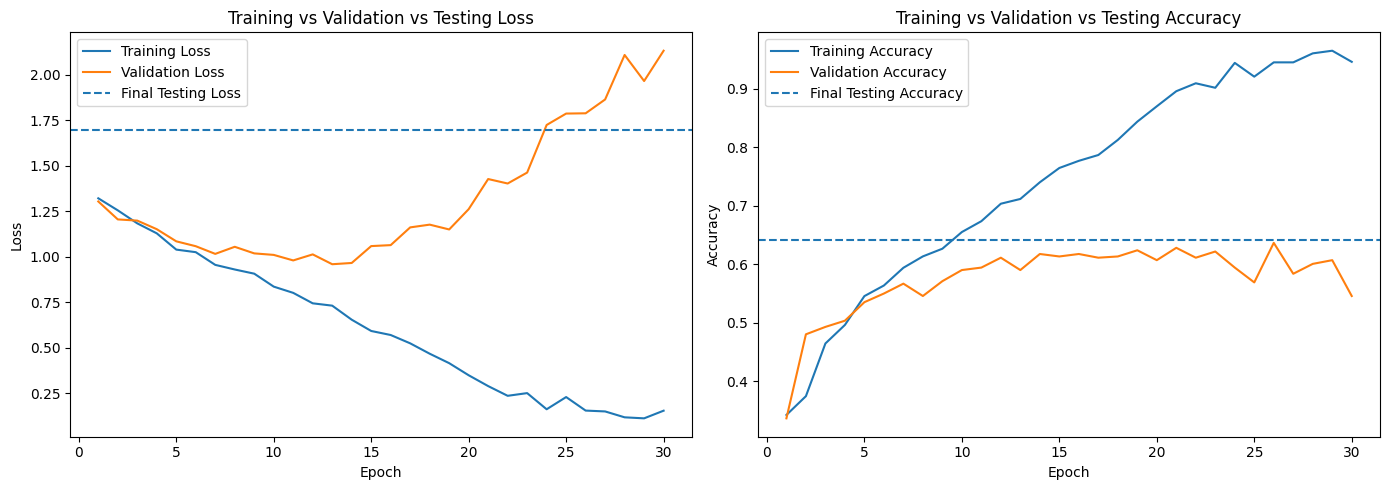

In [29]:
epochs_range = range(1, EPOCHS + 1)

plt.figure(figsize=(14, 5))

# Loss Curve
plt.subplot(1, 2, 1)

plt.plot(epochs_range, history["train_loss"], label="Training Loss")

plt.plot(epochs_range, history["val_loss"], label="Validation Loss")

plt.axhline(y=history["test_loss"], linestyle="--", label="Final Testing Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation vs Testing Loss")
plt.legend()


# Accuracy Curve
plt.subplot(1, 2, 2)

plt.plot(epochs_range, history["train_acc"], label="Training Accuracy")

plt.plot(epochs_range, history["val_acc"], label="Validation Accuracy")

plt.axhline(y=history["test_acc"], linestyle="--", label="Final Testing Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs Validation vs Testing Accuracy")
plt.legend()

plt.tight_layout()
plt.show()


# Confusion Matrix

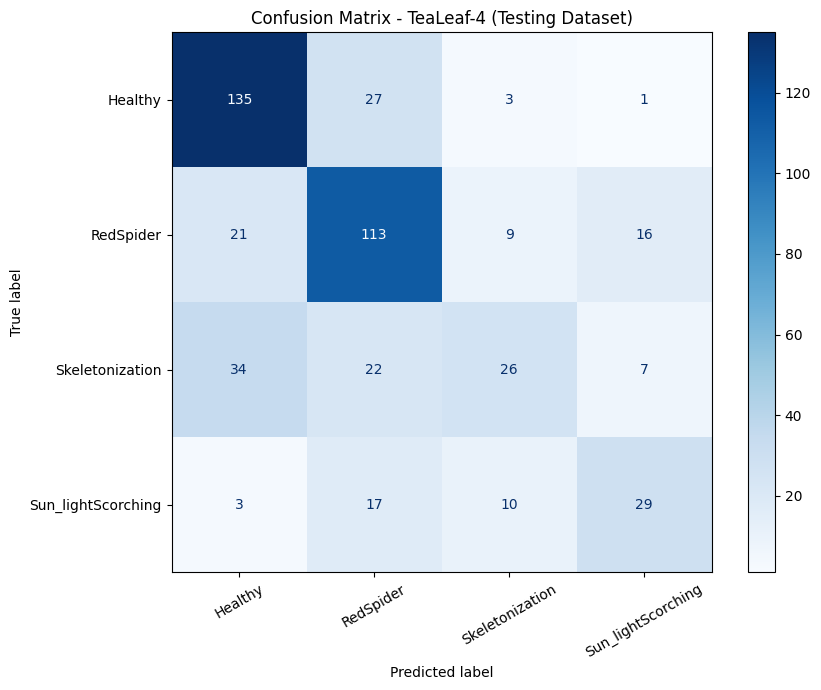

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Model Evaluation Mode
model.eval()

all_labels = []
all_preds = []

# Get predictions from Testing Dataset
with torch.no_grad():

    for imgs, labels in test_loader:

        imgs = imgs.to(device)
        labels = labels.to(device)

        outputs = model(imgs)

        predictions = outputs.argmax(1)

        all_labels.extend(labels.cpu().numpy())
        all_preds.extend(predictions.cpu().numpy())


# Calculate Confusion Matrix
cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(len(train_ds.classes)))
)

# Display Confusion Matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_ds.classes
)

fig, ax = plt.subplots(figsize=(9, 7))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Confusion Matrix - TeaLeaf-4 (Testing Dataset)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

# Data Augmentation Transform

In [23]:
# Training Transform WITH Augmentation
train_transform = transforms.Compose([

    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomRotation(
        degrees=15,
        fill=(255, 255, 255)
    ),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15
    ),

    transforms.ToTensor()
])


# Validation and Testing Transform WITHOUT Augmentation
eval_transform = transforms.Compose([

    transforms.Resize((IMG_SIZE, IMG_SIZE)),

    transforms.ToTensor()
])


print("Training Augmentation Ready!")
print("Validation and Testing: Basic Transform")


Training Augmentation Ready!
Validation and Testing: Basic Transform


# Create Augmented Dataset and DataLoader

In [24]:
# Training Dataset with Augmentation
train_ds_aug = datasets.ImageFolder(
    train_dir,
    transform=train_transform
)

# Validation Dataset without Augmentation
val_ds_clean = datasets.ImageFolder(
    val_dir,
    transform=eval_transform
)

# Testing Dataset without Augmentation
test_ds_clean = datasets.ImageFolder(
    test_dir,
    transform=eval_transform
)


# DATALOADER

train_loader_aug = DataLoader(
    train_ds_aug,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader_clean = DataLoader(
    val_ds_clean,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader_clean = DataLoader(
    test_ds_clean,
    batch_size=BATCH_SIZE,
    shuffle=False
)


# DATASET INFORMATION

print("Classes:", train_ds_aug.classes)

print("Training Images:", len(train_ds_aug))
print("Validation Images:", len(val_ds_clean))
print("Testing Images:", len(test_ds_clean))

print("-----------------------------")

print("Training Batches:", len(train_loader_aug))
print("Validation Batches:", len(val_loader_clean))
print("Testing Batches:", len(test_loader_clean))

print("-----------------------------")

print("Class Mapping:", train_ds_aug.class_to_idx)

assert train_ds_aug.class_to_idx == val_ds_clean.class_to_idx
assert train_ds_aug.class_to_idx == test_ds_clean.class_to_idx

print("All Class Mappings Match!")


Classes: ['Healthy', 'RedSpider', 'Skeletonization', 'Sun_lightScorching']
Training Images: 2208
Validation Images: 473
Testing Images: 473
-----------------------------
Training Batches: 69
Validation Batches: 15
Testing Batches: 15
-----------------------------
Class Mapping: {'Healthy': 0, 'RedSpider': 1, 'Skeletonization': 2, 'Sun_lightScorching': 3}
All Class Mappings Match!


# Visualize Data Augmentation

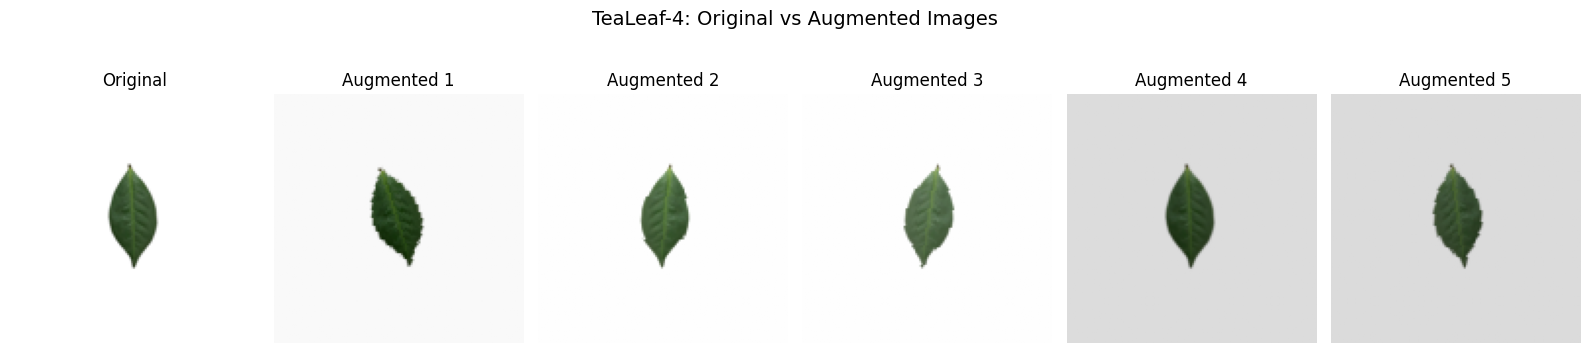

In [25]:
# Select one training image
sample_path, sample_label = train_ds_aug.samples[0]

original_image = Image.open(sample_path).convert("RGB")

original_image = original_image.resize(
    (IMG_SIZE, IMG_SIZE)
)

plt.figure(figsize=(16, 4))

# Original Image
plt.subplot(1, 6, 1)

plt.imshow(original_image)

plt.title("Original")

plt.axis("off")


# Five Random Augmentations
for i in range(5):

    aug_img, _ = train_ds_aug[0]

    plt.subplot(1, 6, i + 2)

    plt.imshow(aug_img.permute(1, 2, 0))

    plt.title(f"Augmented {i+1}")

    plt.axis("off")


plt.suptitle(
    f"TeaLeaf-4: Original vs Augmented Images",
    fontsize=14
)

plt.tight_layout()

plt.show()


# TEALEAF-4 CNN ARCHITECTURE

In [26]:
class SimpleCNN(nn.Module):

    def __init__(self, p_dropout=DROPOUT):

        super().__init__()


        self.conv1 = nn.Conv2d( 3, FEATURE_MAPS[0], kernel_size=KERNEL_SIZE, stride=STRIDE, padding=PADDING )

        self.conv2 = nn.Conv2d( FEATURE_MAPS[0], FEATURE_MAPS[1], kernel_size=KERNEL_SIZE, stride=STRIDE, padding=PADDING )

        self.conv3 = nn.Conv2d( FEATURE_MAPS[1], FEATURE_MAPS[2], kernel_size=KERNEL_SIZE, stride=STRIDE, padding=PADDING )

        self.pool = nn.MaxPool2d(2, 2)


        self.dropout = nn.Dropout(p_dropout)

        self.fc1 = nn.Linear( FEATURE_MAPS[2] * (IMG_SIZE // 8) * (IMG_SIZE // 8), HIDDEN_UNITS )

        self.fc2 = nn.Linear( HIDDEN_UNITS, NUM_CLASSES )

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = self.pool(F.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = self.dropout(x)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


# Build New Model
model = SimpleCNN(p_dropout=DROPOUT).to(device)

print(model)

n_params = sum( p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTotal Trainable Parameters:", f"{n_params:,}")

print("Dropout:", model.dropout.p)

print("Image Size:", IMG_SIZE)

print("Number of Classes:", NUM_CLASSES)

print("Model Device:", next(model.parameters()).device)


SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.25, inplace=False)
  (fc1): Linear(in_features=16384, out_features=64, bias=True)
  (fc2): Linear(in_features=64, out_features=4, bias=True)
)

Total Trainable Parameters: 1,072,484
Dropout: 0.25
Image Size: 128
Number of Classes: 4
Model Device: cuda:0


# TRAINING FUNCTION
# AUGMENTATION + DROPOUT

In [27]:
def train_model(
    model,
    train_loader,
    val_loader,
    test_loader,
    epochs=35,
    lr=LEARNING_RATE,
    checkpoint_path="/kaggle/working/best_model_tealeaf_aug_d025.pth"
):

    criterion = nn.CrossEntropyLoss()

    # Optimizer Selection
    if OPTIMIZER_NAME == "Adam":

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=lr
        )

    elif OPTIMIZER_NAME == "SGD":

        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=lr,
            momentum=0.9
        )

    else:
        raise ValueError("Unsupported Optimizer")


    # Store Training History
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }

    # Best Model Checkpoint
    best_val_acc = -1.0
    best_epoch = 0


    for epoch in range(epochs):

        # TRAINING

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for imgs, labels in train_loader:

            imgs = imgs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(imgs)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * imgs.size(0)

            correct += (outputs.argmax(1) == labels).sum().item()

            total += labels.size(0)


        train_loss = running_loss / total
        train_acc = correct / total


        # VALIDATION

        model.eval()

        running_loss = 0.0
        correct = 0
        total = 0

        with torch.no_grad():

            for imgs, labels in val_loader:

                imgs = imgs.to(device)
                labels = labels.to(device)

                outputs = model(imgs)

                loss = criterion(outputs, labels)

                running_loss += loss.item() * imgs.size(0)

                correct += (outputs.argmax(1) == labels).sum().item()

                total += labels.size(0)


        val_loss = running_loss / total
        val_acc = correct / total


        # SAVE BEST MODEL

        if val_acc > best_val_acc:

            best_val_acc = val_acc

            best_epoch = epoch + 1

            torch.save(
                model.state_dict(),
                checkpoint_path
            )


        # STORE HISTORY

        history["train_loss"].append(train_loss)

        history["val_loss"].append(val_loss)

        history["train_acc"].append(train_acc)

        history["val_acc"].append(val_acc)


        print(
            f"Epoch {epoch+1:2d}/{epochs}  "
            f"train_loss={train_loss:.3f} "
            f"train_acc={train_acc:.3f}  |  "
            f"val_loss={val_loss:.3f} "
            f"val_acc={val_acc:.3f}"
        )


    # BEST VALIDATION RESULT

    print("\nBest Validation Accuracy:", round(best_val_acc, 4))

    print("Best Epoch:", best_epoch)


    # LOAD BEST MODEL

    model.load_state_dict(
        torch.load(
            checkpoint_path,
            map_location=device
        )
    )


    # FINAL TESTING

    model.eval()

    running_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():

        for imgs, labels in test_loader:

            imgs = imgs.to(device)
            labels = labels.to(device)

            outputs = model(imgs)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * imgs.size(0)

            correct += (outputs.argmax(1) == labels).sum().item()

            total += labels.size(0)


    test_loss = running_loss / total

    test_acc = correct / total


    print("\n FINAL TEST RESULTS ")

    print("Test Loss:", round(test_loss, 4))

    print("Test Accuracy:", round(test_acc, 4))


    # Store Testing Results
    history["test_loss"] = test_loss

    history["test_acc"] = test_acc


    return history


# Execute The Training Function after Augmentation

In [28]:
# Build a fresh model
model = SimpleCNN(p_dropout=DROPOUT).to(device)


# Train and Evaluate
history_aug = train_model(
    model,

    train_loader_aug,

    val_loader_clean,

    test_loader_clean,

    epochs=35,

    lr=LEARNING_RATE,

    checkpoint_path="/kaggle/working/best_model_tealeaf_aug_d025.pth"
)


Epoch  1/35  train_loss=1.319 train_acc=0.349  |  val_loss=1.307 val_acc=0.393
Epoch  2/35  train_loss=1.301 train_acc=0.356  |  val_loss=1.288 val_acc=0.357
Epoch  3/35  train_loss=1.264 train_acc=0.380  |  val_loss=1.240 val_acc=0.366
Epoch  4/35  train_loss=1.237 train_acc=0.420  |  val_loss=1.189 val_acc=0.431
Epoch  5/35  train_loss=1.191 train_acc=0.449  |  val_loss=1.158 val_acc=0.518
Epoch  6/35  train_loss=1.109 train_acc=0.490  |  val_loss=1.053 val_acc=0.556
Epoch  7/35  train_loss=1.068 train_acc=0.514  |  val_loss=1.030 val_acc=0.558
Epoch  8/35  train_loss=1.059 train_acc=0.531  |  val_loss=0.991 val_acc=0.579
Epoch  9/35  train_loss=1.020 train_acc=0.548  |  val_loss=0.998 val_acc=0.558
Epoch 10/35  train_loss=1.014 train_acc=0.562  |  val_loss=0.960 val_acc=0.596
Epoch 11/35  train_loss=0.986 train_acc=0.579  |  val_loss=0.977 val_acc=0.628
Epoch 12/35  train_loss=0.974 train_acc=0.588  |  val_loss=0.932 val_acc=0.626
Epoch 13/35  train_loss=0.971 train_acc=0.578  |  va

# TRAINING CURVES After Augmentation

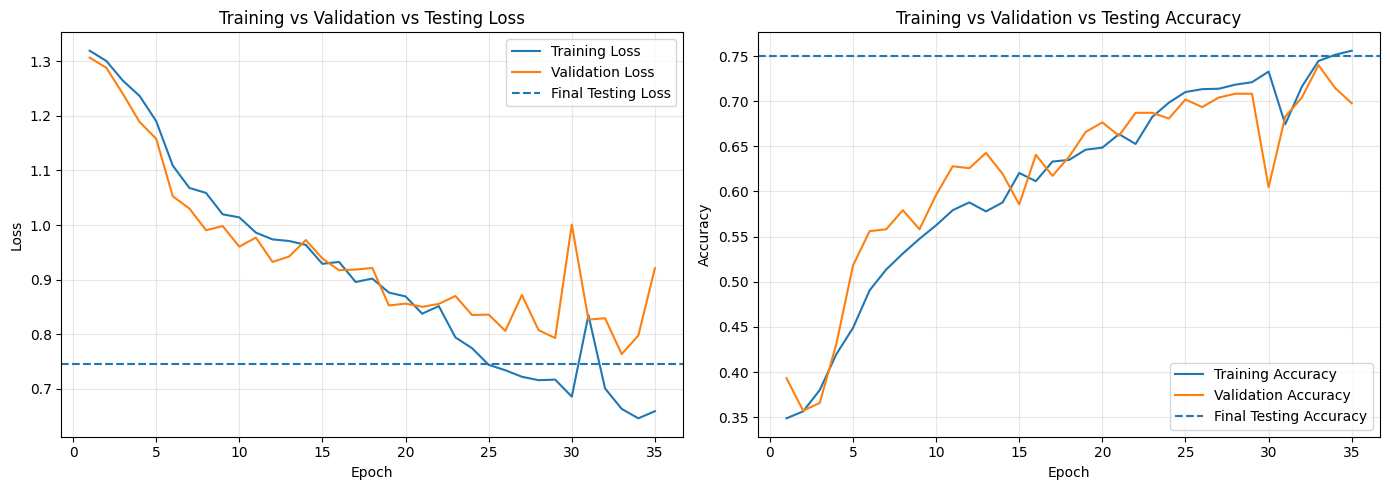

In [29]:


epochs_range = range(1, len(history_aug["train_loss"]) + 1)

plt.figure(figsize=(14, 5))


# Loss Curve
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    history_aug["train_loss"],
    label="Training Loss"
)

plt.plot(
    epochs_range,
    history_aug["val_loss"],
    label="Validation Loss"
)

plt.axhline(
    y=history_aug["test_loss"],
    linestyle="--",
    label="Final Testing Loss"
)

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Training vs Validation vs Testing Loss")

plt.legend()

plt.grid(alpha=0.3)


# Accuracy Curve
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    history_aug["train_acc"],
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    history_aug["val_acc"],
    label="Validation Accuracy"
)

plt.axhline(
    y=history_aug["test_acc"],
    linestyle="--",
    label="Final Testing Accuracy"
)

plt.xlabel("Epoch")

plt.ylabel("Accuracy")

plt.title("Training vs Validation vs Testing Accuracy")

plt.legend()

plt.grid(alpha=0.3)


plt.tight_layout()

plt.show()


# TESTING CONFUSION MATRIX after Augmentation

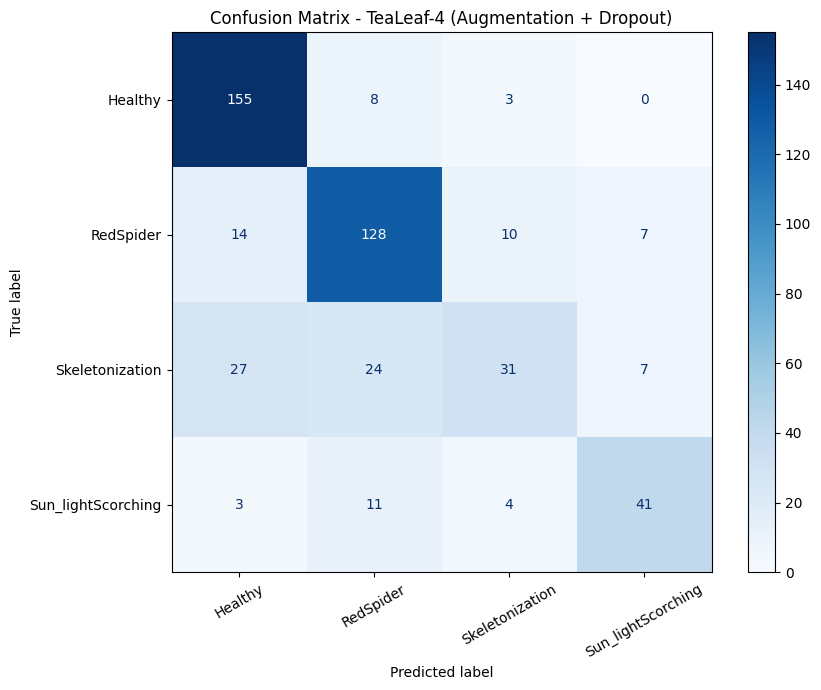

In [30]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

model.eval()

all_labels = []
all_preds = []

with torch.no_grad():

    for imgs, labels in test_loader_clean:

        imgs = imgs.to(device)

        outputs = model(imgs)

        predictions = outputs.argmax(1)

        all_labels.extend(labels.numpy())

        all_preds.extend(predictions.cpu().numpy())


# Calculate Confusion Matrix
cm = confusion_matrix(
    all_labels,
    all_preds,
    labels=list(range(NUM_CLASSES))
)


# Display
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=train_ds_aug.classes
)

fig, ax = plt.subplots(figsize=(9, 7))

disp.plot(
    cmap="Blues",
    values_format="d",
    ax=ax
)

plt.title("Confusion Matrix - TeaLeaf-4 (Augmentation + Dropout)")

plt.xticks(rotation=30)

plt.tight_layout()

plt.show()
